# Dados e Aprendizagem Automática 26/27
### Part VI

## **I - Ensemble Learning using Titanic Dataset**

You may need to install <em>**xgboost**</em>. Use one of the following commands:

<code>conda install -c conda-forge xgboost</code>

<code>pip install xgboost</code>

In [3]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedShuffleSplit
from sklearn import tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier, BaggingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
#import xgboost as xgb
from xgboost.sklearn import XGBClassifier

from sklearn.metrics import classification_report
%matplotlib inline

*Load the CSV - Titanic*

In [5]:
df = pd.read_csv('titanic.csv')

**EDA**

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<Axes: >

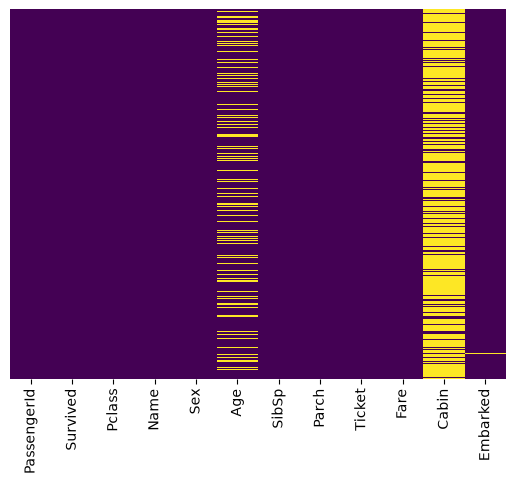

In [8]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')

Let's analyse the <em>Age</em> distribution with the ticket class, <em>Pclass</em>:

<Axes: xlabel='Pclass', ylabel='Age'>

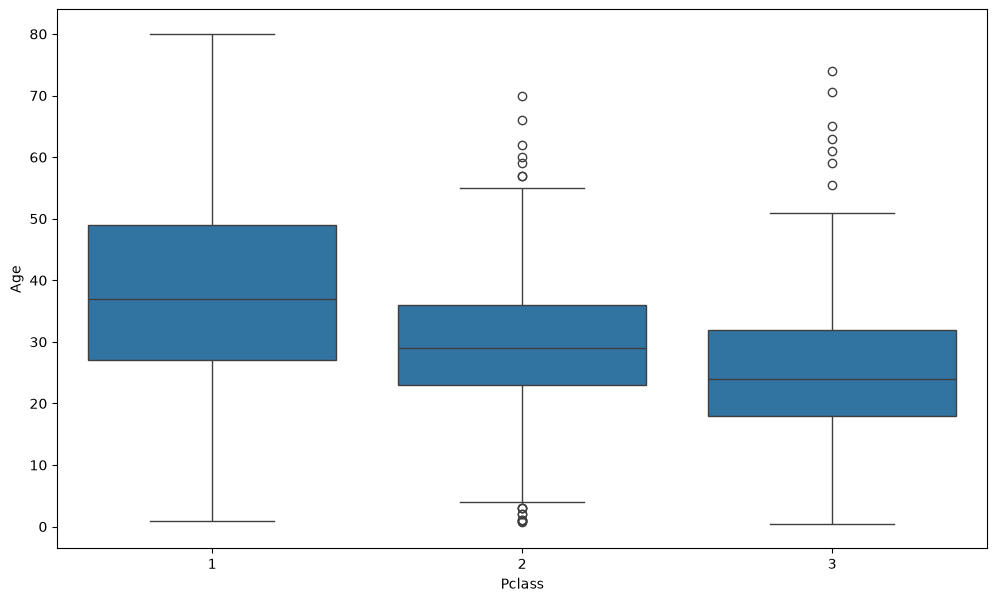

In [9]:
plt.figure(figsize = (12, 7))
sns.boxplot(x = 'Pclass', y = 'Age', data = df)

Let's impute the missing values in <em>Age</em> with the ticket class, <em>Pclass</em>:

In [ ]:
df['Age'] = df['Age'].fillna(df.groupby('Pclass')['Age'].transform('median'))

We will drop features: <em>Cabin</em>, <em>Sex</em>, <em>Embarked</em>, <em>Name</em> and <em>Ticket</em>

In [ ]:
df.('Cabin', axis = 2, inplace = True)
df.(inplace = True)

In [ ]:
df.(['Sex', 'Embarked', 'Name', 'Ticket'], axis = 1,inplace = False)

In [ ]:
df.

*Split the data*

In [ ]:
y = df.drop('Survived', axis = 1)
X = df['Survived']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = , random_state = )

In [ ]:
X_train.shape, y_train.shape, X_test.shape, y_test.

## **II - Models**

Let's try different models. We will implement Decision Tree, Logistic Regression and Random Forest models for comparison with the Ensemble Learning Models.

### Decision Tree

In [ ]:
 = DecisionTreeClassifier()

In [ ]:
dt_model.fit()

Accuracy of the model

In [ ]:
dt_score = dt_model.score()

In [ ]:
print("Accuracy: %.2f%%" % ( * 100))

Predictions

In [ ]:
dt_predictions = dt_model.predict()

In [ ]:
print((y_test, dt_predictions))

Save the model's accuracy in a dictionary for latter comparison

In [ ]:
results = {'DT': }

### Logistic Regression

<code>sklearn.linear_model.LogisticRegression(penalty='l2', *, dual=False, tol=0.0001, C=1.0, fit_intercept=True, intercept_scaling=1, class_weight=None, random_state=None, solver='lbfgs', max_iter=100, multi_class='deprecated', verbose=0, warm_start=False, n_jobs=None, l1_ratio=None)</code>

In [ ]:
lr_model = Regression()

In [ ]:
lr_model.fit()

Accuracy of the model

In [ ]:
lr_score = lr_model.()

In [ ]:
print("Accuracy: %.2f%%" % ( * 100))

Predictions:

In [ ]:
lr_predictions = lr_model.()

In [ ]:
print((y_test, lr_predictions))

Save the model's accuracy

In [ ]:
results['LogR'] = 

### Random Forest

<code>sklearn.ensemble.RandomForestClassifier(n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)</code>

In [ ]:
rf_model = RandomForest()

In [ ]:
rf_model.(X_train, y_train)

Accuracy of the model

In [ ]:
rf_score = rf_model.(X_test, y_test)

In [ ]:
print("Accuracy: %.2f%%" % ( * 100))

Predictions

In [ ]:
rf_predictions = rf_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['RF'] = 

## **III - Ensemble Learning Models**

### Max Voting

#### Majority Class Labels (Majority/Hard Voting)

<code>sklearn.ensemble.VotingClassifier(estimators, *, voting='hard', weights=None, n_jobs=None, flatten_transform=True, verbose=False)</code>

In [ ]:
hvt_model = VotingClassifier()

In [ ]:
hvt_model.(X_train, y_train)

Accuracy of each model using *cross_val_score*

In [ ]:
for model, label in zip([], []):
    hvt_score = cross_val_score(model, X_test, y_test, scoring = '', cv = )
    print("Accuracy: %0.2f (+/- %0.2f) [%s]" % (hvt_score.mean(), hvt_score.std(), label))

Accuracy of the max voted model

In [ ]:
hvt_score = hvt_model.(X_test, y_test)
print("Accuracy: %.2f%%" % (*100))

Predictions

In [ ]:
hvt_predictions = hvt_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['HVotW']= 

### Bagging *(Bootstrap Aggregating)*

<code>sklearn.model_selection.StratifiedShuffleSplit(n_splits=10, *, test_size=None, train_size=None, random_state=None)</code>

In [ ]:
sss = StratifiedShuffleSplit()

<code>sklearn.ensemble.BaggingClassifier(estimator=None, n_estimators=10, *, max_samples=1.0, max_features=1.0, bootstrap=True, bootstrap_features=False, oob_score=False, warm_start=False, n_jobs=None, random_state=None, verbose=0)</code>

In [ ]:
bg_dt_model = BaggingClassifier()

In [ ]:
n_estimators = [10, 40, 60, 80, 100, 160]

In [ ]:
parameters = {'n_estimators': n_estimators}

In [ ]:
grid_bg = GridSearchCV()

In [ ]:
grid_bg.fit(X_train, y_train)

Best estimator

In [ ]:
bst_bg_model = grid_bg.

In [ ]:
print(bst_bg_model)

In [ ]:
bst_bg_model.(X_train, y_train)

Accuracy of the model

In [ ]:
bst_bg_score = bst_bg_model.(X_test, y_test)

In [ ]:
print("Accuracy: %.2f%%" % (*100))

Predictions

In [ ]:
bg_predictions = bst_bg_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['BaggDT']= 

#### Random Forest

<code>sklearn.ensemble.RandomForestClassifier(n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)</code>

In [ ]:
bg_rf_model = RandomForest()

In [ ]:
bg_rf_model.(X_train, y_train)

Accuracy of the model

In [ ]:
bg_rf_score = bg_rf_model.(X_test, y_test)

In [ ]:
print("Accuracy: %.2f%%" % ( * 100))

Predictions

In [ ]:
bg_rf_predictions = bg_rf_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['BaggRF'] = 

### Boosting

#### Gradient Boosting

<code>sklearn.ensemble.GradientBoostingClassifier(*, loss='log_loss', learning_rate=0.1, n_estimators=100, subsample=1.0, criterion='friedman_mse', min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_depth=3, min_impurity_decrease=0.0, init=None, random_state=None, max_features=None, verbose=0, max_leaf_nodes=None, warm_start=False, validation_fraction=0.1, n_iter_no_change=None, tol=0.0001, ccp_alpha=0.0))</code>

In [ ]:
gbc_model = GradientBoostingClassifier()

In [ ]:
gbc_model.(X_train, y_train)

Accuracy of the model

In [ ]:
gbc_score = gbc_model.(X_test, y_test)

In [ ]:
print("Accuracy: %.2f%%" % (*100))

Predictions

In [ ]:
gbc_predictions = gbc_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['GB'] = 

#### XGBoost

<code>xgboost.sklearn.XGBClassifier(base_score=None, booster=None, callbacks=None, colsample_bylevel=None, colsample_bynode=None,colsample_bytree=None, device=None, early_stopping_rounds=None,enable_categorical=False, eval_metric=None, feature_types=None,gamma=None, grow_policy=None, importance_type=None,interaction_constraints=None, learning_rate=None, max_bin=None,max_cat_threshold=None, max_cat_to_onehot=None,max_delta_step=None, max_depth=None, max_leaves=None, min_child_weight=None, missing=nan, monotone_constraints=None,multi_strategy=None, n_estimators=None, n_jobs=None,num_parallel_tree=None, random_state=None, ...)</code>

In [ ]:
xgb_model = XGBClassifier()

In [ ]:
xgb_model.fit(X_train, )

Accuracy of the model

In [ ]:
xgb_score = xgb_model.score(X_test, )

In [ ]:
print("Accuracy: %.2f%%" % ( * 100))

Predictions

In [ ]:
xgb_predictions = xgb_model.(X_test)

In [ ]:
print(classification_report(, xgb_predictions))

Save the model's accuracy

In [ ]:
results['XGB'] = 

### Stacking

#### StackingClassifier

In [ ]:
estimators = []

<code>sklearn.ensemble.StackingClassifier(estimators, final_estimator=None, *, cv=None, stack_method='auto', n_jobs=None, passthrough=False, verbose=0)</code>

In [ ]:
st_model = StackingClassifier() 

In [ ]:
st_model.fit(X_train, y_train)

Accuracy of the model

In [ ]:
st_score = st_model.score(X_test, )

In [ ]:
print("Accuracy: %.2f%%" % (*100))

Predictions

In [ ]:
st_predictions = st_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['Stack']= 

<code>sklearn.ensemble.VotingClassifier(estimators, *, voting='hard', weights=None, n_jobs=None, flatten_transform=True, verbose=False)</code>

In [ ]:
hvt_model = VotingClassifier()

In [ ]:
hvt_model.fit(X_train, )

Accuracy of each model using *cross_val_score*

In [ ]:
for model, label in zip([dt_model, lr_model, rf_model, hvt_model], ['dt', 'lr', 'rf', 'Ensemble']):
    hvt_score = , scoring = 'accuracy', cv = 5)
    print("Accuracy: %0.2f (+/- %0.2f) [%s]" % (hvt_score.mean(), hvt_score.std(), ))

Accuracy of the max voted model

In [ ]:
hvt_score = hvt_model.score(X_test, y_test)
print("Accuracy: %.2f%%" % (*100))

Predictions

In [ ]:
hvt_predictions = hvt_model.(X_test)

In [ ]:
print(classification_report(y_test, ))

Save the model's accuracy

In [ ]:
results['HVotW']= 

## **IV - Models Accuracy Comparison**

Bar chart with the accuracy of each created model

In [ ]:
fig = plt.figure(figsize = (, ))

mod = list(results.keys())
acc =list(results.values())

plt.bar( color ='lightblue', width = 0.5)
 
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Models accuracy comparison")

Bars' visualization horizontally

In [ ]:
fig, ax = plt.subplots()

y_values = np.arange(len(mod))

ax.barh(align='center')
ax.set_yticks(y_values, labels = mod)

ax.set_xlabel('Accuracy')
ax.set_title('Models accuracy comparison')

plt.show()

Dictionary  with the results

In [ ]:
print("Models accuracy comparison")
for :
    print("%s \t %.2f" % (key, value))

### Which model performed better? Which models are worth tuning?